## 1. Import libraries

In [1]:
import json
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42


## 2. Load data

In [ ]:
PROJECT_DIR = Path(r"C:\Projek\Machine Learning\portfolio\01\retail-sales-forecasting")
DATA_PATH = PROJECT_DIR / "data" / "processed" / "forecasting_features.csv"
OUTPUT_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_data = pd.read_csv(DATA_PATH, parse_dates=["date"])
model_data = model_data.sort_values(["family", "date"]).reset_index(drop=True)

required_columns = {
    "date", "family", "sales", "day_of_week", "day_of_month",
    "month", "year", "lag_1", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
}
missing_columns = required_columns - set(model_data.columns)
if missing_columns:
    raise ValueError(f"Kolom berikut tidak ditemukan: {sorted(missing_columns)}")

print("Shape:", model_data.shape)
print("Date range:", model_data["date"].min(), "to", model_data["date"].max())
print("Families:", sorted(model_data["family"].unique()))
print("Missing values in required columns:")
display(model_data[list(required_columns)].isna().sum())


Shape: (8280, 13)
Date range: 2013-01-29 00:00:00 to 2017-08-15 00:00:00
Families: ['BEVERAGES', 'CLEANING', 'DAIRY', 'GROCERY I', 'PRODUCE']
Missing values in required columns:


day_of_month       0
lag_1              0
lag_7              0
year               0
family             0
sales              0
month              0
lag_28             0
day_of_week        0
rolling_mean_7     0
lag_14             0
rolling_mean_28    0
date               0
dtype: int64

## 3. Define features, target, and helper functions

In [3]:
FEATURES = [
    "family",
    "day_of_week",
    "day_of_month",
    "month",
    "year",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]
TARGET = "sales"

def build_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("family_encoder", OneHotEncoder(handle_unknown="ignore"), ["family"])
        ],
        remainder="passthrough"
    )

def build_rf_model(params):
    return Pipeline(steps=[
        ("preprocessor", build_preprocessor()),
        ("regressor", RandomForestRegressor(
            n_estimators=int(params["n_estimators"]),
            max_depth=params["max_depth"],
            min_samples_split=int(params["min_samples_split"]),
            min_samples_leaf=int(params["min_samples_leaf"]),
            max_features=params["max_features"],
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    total_actual = np.abs(y_true).sum()
    wape = (
        np.abs(y_true - y_pred).sum() / total_actual * 100
        if total_actual != 0 else np.nan
    )

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "WAPE (%)": wape
    }

def recursive_forecast(model, history_data, forecast_dates):
    """Forecast each family recursively for the requested dates."""
    predictions = []
    families = sorted(history_data["family"].unique())

    for family in families:
        history = (
            history_data.loc[history_data["family"] == family]
            .sort_values("date")["sales"]
            .astype(float)
            .tolist()
        )

        if len(history) < 28:
            raise ValueError(
                f"History untuk {family} kurang dari 28 observasi; "
                "lag_28 tidak dapat dibentuk."
            )

        for forecast_date in pd.DatetimeIndex(forecast_dates):
            row = pd.DataFrame([{
                "family": family,
                "day_of_week": forecast_date.dayofweek,
                "day_of_month": forecast_date.day,
                "month": forecast_date.month,
                "year": forecast_date.year,
                "lag_1": history[-1],
                "lag_7": history[-7],
                "lag_14": history[-14],
                "lag_28": history[-28],
                "rolling_mean_7": np.mean(history[-7:]),
                "rolling_mean_28": np.mean(history[-28:])
            }])

            prediction = float(model.predict(row[FEATURES])[0])
            prediction = max(0.0, prediction)

            predictions.append({
                "date": forecast_date,
                "family": family,
                "prediction": prediction
            })
            history.append(prediction)

    return pd.DataFrame(predictions)

def moving_average_forecast(history_data, forecast_dates, window=7):
    predictions = []

    for family in sorted(history_data["family"].unique()):
        history = (
            history_data.loc[
                history_data["family"] == family
            ]
            .sort_values("date")["sales"]
            .astype(float)
            .tolist()
        )

        for forecast_date in forecast_dates:
            prediction = np.mean(history[-window:])
            prediction = max(0.0, prediction)

            predictions.append({
                "date": forecast_date,
                "family": family,
                "ma_prediction": prediction
            })

            # Recursive: hasil prediksi masuk ke history
            history.append(prediction)

    return pd.DataFrame(predictions)


## 4. Configure tuning and validation periods

In [ ]:
# 1. HYPERPARAMETER TUNING: 4 WINDOWS × 7 DAYS

TUNING_WINDOWS = [
    {
        "fold": "T1",
        "train_end": pd.Timestamp("2017-05-23"),
        "val_start": pd.Timestamp("2017-05-24"),
        "val_end": pd.Timestamp("2017-05-30")
    },
    {
        "fold": "T2",
        "train_end": pd.Timestamp("2017-05-30"),
        "val_start": pd.Timestamp("2017-05-31"),
        "val_end": pd.Timestamp("2017-06-06")
    },
    {
        "fold": "T3",
        "train_end": pd.Timestamp("2017-06-06"),
        "val_start": pd.Timestamp("2017-06-07"),
        "val_end": pd.Timestamp("2017-06-13")
    },
    {
        "fold": "T4",
        "train_end": pd.Timestamp("2017-06-13"),
        "val_start": pd.Timestamp("2017-06-14"),
        "val_end": pd.Timestamp("2017-06-20")
    }
]


# 2. ROLLING-ORIGIN VALIDATION: 8 FOLDS × 7 DAYS

VALIDATION_START = pd.Timestamp("2017-06-21")
VALIDATION_END = pd.Timestamp("2017-08-15")

HORIZON = 7


# 3. CHECK DATA AVAILABILITY

data_start = model_data["date"].min()
data_end = model_data["date"].max()

print(f"Actual data available: {data_start.date()} to {data_end.date()}")

print("\nHyperparameter Tuning:")
for window in TUNING_WINDOWS:
    print(
        f'{window["fold"]}: '
        f'Train until {window["train_end"].date()} | '
        f'Validation {window["val_start"].date()} '
        f'to {window["val_end"].date()}'
    )

print(
    f"\nRolling-origin Validation: "
    f"{VALIDATION_START.date()} to {VALIDATION_END.date()}"
)

print(f"Forecast Horizon: {HORIZON} days")


# 4. VALIDATION CHECKS

# Pastikan data mencakup seluruh periode validation
if data_end < VALIDATION_END:
    raise ValueError(
        f"Data hanya sampai {data_end.date()}, sedangkan konfigurasi "
        f"validation membutuhkan data sampai {VALIDATION_END.date()}. "
        "Sesuaikan tanggal berdasarkan data aktual."
    )

# Pastikan data mencakup seluruh periode tuning
if data_start > TUNING_WINDOWS[0]["train_end"] - pd.Timedelta(days=27):
    raise ValueError(
        "Data historis tidak cukup untuk memenuhi kebutuhan lag_28 "
        "pada window tuning pertama."
    )

# Pastikan seluruh tuning window valid
for window in TUNING_WINDOWS:

    if window["train_end"] >= window["val_start"]:
        raise ValueError(
            f"{window['fold']}: training harus berakhir sebelum validation."
        )

    window_days = (
        window["val_end"] - window["val_start"]
    ).days + 1

    if window_days != HORIZON:
        raise ValueError(
            f"{window['fold']}: periode validation harus {HORIZON} hari."
        )

# Pastikan tuning dan rolling validation tidak overlap
if TUNING_WINDOWS[-1]["val_end"] >= VALIDATION_START:
    raise ValueError(
        "Periode tuning overlap dengan rolling-origin validation."
    )

# Pastikan jumlah validation folds tepat
validation_days = (
    VALIDATION_END - VALIDATION_START
).days + 1

if validation_days % HORIZON != 0:
    raise ValueError(
        "Periode validation tidak dapat dibagi secara merata "
        "berdasarkan forecast horizon."
    )

N_VALIDATION_FOLDS = validation_days // HORIZON

print("\nConfiguration checks passed.")
print(f"Number of tuning windows: {len(TUNING_WINDOWS)}")
print(f"Number of validation folds: {N_VALIDATION_FOLDS}")

Actual data available: 2013-01-29 to 2017-08-15

Hyperparameter Tuning:
T1: Train until 2017-05-23 | Validation 2017-05-24 to 2017-05-30
T2: Train until 2017-05-30 | Validation 2017-05-31 to 2017-06-06
T3: Train until 2017-06-06 | Validation 2017-06-07 to 2017-06-13
T4: Train until 2017-06-13 | Validation 2017-06-14 to 2017-06-20

Rolling-origin Validation: 2017-06-21 to 2017-08-15
Forecast Horizon: 7 days

Configuration checks passed.
Number of tuning windows: 4
Number of validation folds: 8


## 5. Hyperparameter tuning on a separate tuning window

In [ ]:
# MULTI-WINDOW HYPERPARAMETER TUNING
# 4 WINDOWS × 7 DAYS

# Grid hyperparameter
PARAM_GRID = {
    "n_estimators": [200, 400],
    "max_depth": [10, 15, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": [0.7, 1.0]
}

param_combinations = [
    dict(zip(PARAM_GRID.keys(), values))
    for values in product(*PARAM_GRID.values())
]

# Menyimpan hasil seluruh eksperimen
tuning_rows = []

# Loop setiap kombinasi hyperparameter
for idx, params in enumerate(param_combinations, start=1):

    fold_results = []

    # Uji kombinasi pada 4 tuning windows
    for window in TUNING_WINDOWS:

        train_end = window["train_end"]
        val_start = window["val_start"]
        val_end = window["val_end"]

        # Training data
        tuning_train = model_data[
            model_data["date"] <= train_end
        ].copy()

        # Actual validation data
        tuning_actual = model_data[
            model_data["date"].between(val_start, val_end)
        ].copy()

        # Forecast dates
        tuning_dates = pd.date_range(
            start=val_start,
            end=val_end,
            freq="D"
        )

        if tuning_train.empty or tuning_actual.empty:
            raise ValueError(
                f"Data kosong pada tuning window {window['fold']}."
            )

        # Pastikan setiap family memiliki 7 tanggal aktual
        expected_families = set(model_data["family"].unique())

        for family in expected_families:

            n_dates = tuning_actual.loc[
                tuning_actual["family"] == family,
                "date"
            ].nunique()

            if n_dates != HORIZON:
                raise ValueError(
                    f'{window["fold"]}: {family} hanya memiliki '
                    f'{n_dates} tanggal aktual.'
                )

        # Build dan train Random Forest
        model = build_rf_model(params)

        model.fit(
            tuning_train[FEATURES],
            tuning_train[TARGET]
        )

        # Recursive forecasting
        predictions = recursive_forecast(
            model,
            tuning_train,
            tuning_dates
        )

        # Gabungkan prediction dengan actual
        merged = tuning_actual[
            ["date", "family", "sales"]
        ].merge(
            predictions,
            on=["date", "family"],
            validate="one_to_one"
        )

        # Evaluasi setiap window
        metrics = calculate_metrics(
            merged["sales"],
            merged["prediction"]
        )

        fold_results.append({
            "fold": window["fold"],
            **metrics
        })

    # Hitung rata-rata metrik dari 4 windows
    avg_mae = np.mean([
        result["MAE"] for result in fold_results
    ])

    avg_rmse = np.mean([
        result["RMSE"] for result in fold_results
    ])

    avg_wape = np.mean([
        result["WAPE (%)"] for result in fold_results
    ])

    # Simpan hasil tuning
    tuning_rows.append({
        **params,

        "T1_WAPE": fold_results[0]["WAPE (%)"],
        "T2_WAPE": fold_results[1]["WAPE (%)"],
        "T3_WAPE": fold_results[2]["WAPE (%)"],
        "T4_WAPE": fold_results[3]["WAPE (%)"],

        "Average MAE": avg_mae,
        "Average RMSE": avg_rmse,
        "Average WAPE (%)": avg_wape
    })

    if idx % 10 == 0 or idx == len(param_combinations):
        print(
            f"Completed {idx}/{len(param_combinations)} "
            f"hyperparameter combinations"
        )


# RANKING HYPERPARAMETER

tuning_results = (
    pd.DataFrame(tuning_rows)
    .sort_values(
        ["Average WAPE (%)", "Average RMSE"]
    )
    .reset_index(drop=True)
)

display(tuning_results.head(10))

Completed 10/48 hyperparameter combinations
Completed 20/48 hyperparameter combinations
Completed 30/48 hyperparameter combinations
Completed 40/48 hyperparameter combinations
Completed 48/48 hyperparameter combinations


,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,T1_WAPE,T2_WAPE,T3_WAPE,T4_WAPE,Average MAE,Average RMSE,Average WAPE (%)
0,200,15.0,5,2,0.7,8.109303,8.830797,7.102188,7.376059,11263.039944,17703.701298,7.854587
1,200,NaN,5,2,1.0,8.746633,8.709450,6.949662,7.039510,11263.048714,17508.164579,7.861314
2,400,15.0,2,1,1.0,8.504797,8.976495,6.688543,7.280632,11277.839087,17634.093915,7.862617
3,400,15.0,5,2,0.7,8.236832,8.909035,7.105528,7.280259,11305.841902,17851.976346,7.882913
4,200,15.0,5,2,1.0,8.693570,8.841107,6.936071,7.086867,11308.677856,17575.576918,7.889404
5,400,NaN,2,1,0.7,8.451354,8.849326,6.911843,7.358229,11313.880982,17919.792462,7.892688
6,200,NaN,2,2,1.0,8.736643,8.717295,6.854127,7.268927,11307.705996,17529.900664,7.894248
7,400,10.0,5,2,1.0,8.175166,9.246315,6.992809,7.165179,11339.948882,17762.669750,7.894867
8,400,10.0,2,2,1.0,8.163155,9.217033,7.014886,7.197975,11343.180087,17759.526357,7.898262
9,200,NaN,5,1,1.0,8.701473,9.157466,6.749532,6.988995,11338.162206,17635.972950,7.899367


## 6. Select and lock the best parameters

In [6]:
best_params = tuning_results.iloc[0][
    ["n_estimators", "max_depth", "min_samples_split",
     "min_samples_leaf", "max_features"]
].to_dict()

best_params["n_estimators"] = int(best_params["n_estimators"])
best_params["max_depth"] = (
    None if pd.isna(best_params["max_depth"]) else int(best_params["max_depth"])
)
best_params["min_samples_split"] = int(best_params["min_samples_split"])
best_params["min_samples_leaf"] = int(best_params["min_samples_leaf"])
best_params["max_features"] = float(best_params["max_features"])

print("Locked parameters:")
print(best_params)


Locked parameters:
{'n_estimators': 200, 'max_depth': 15, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 0.7}


## 7. Generate non-overlapping rolling-origin folds

In [7]:
folds = []
fold_start = VALIDATION_START
fold_number = 1

while fold_start + pd.Timedelta(days=HORIZON - 1) <= VALIDATION_END:
    fold_end = fold_start + pd.Timedelta(days=HORIZON - 1)
    cutoff = fold_start - pd.Timedelta(days=1)

    folds.append({
        "fold": fold_number,
        "cutoff": cutoff,
        "start": fold_start,
        "end": fold_end
    })

    fold_number += 1
    fold_start = fold_end + pd.Timedelta(days=1)

fold_table = pd.DataFrame(folds)
display(fold_table)

# Verifikasi tidak ada overlap dan semua window tepat 7 hari.
for i, fold in enumerate(folds):
    assert (fold["end"] - fold["start"]).days + 1 == HORIZON
    if i > 0:
        assert folds[i-1]["end"] < fold["start"]


,fold,cutoff,start,end
0,1,2017-06-20,2017-06-21,2017-06-27
1,2,2017-06-27,2017-06-28,2017-07-04
2,3,2017-07-04,2017-07-05,2017-07-11
3,4,2017-07-11,2017-07-12,2017-07-18
4,5,2017-07-18,2017-07-19,2017-07-25
5,6,2017-07-25,2017-07-26,2017-08-01
6,7,2017-08-01,2017-08-02,2017-08-08
7,8,2017-08-08,2017-08-09,2017-08-15


## 8. Run rolling-origin validation

In [8]:
rolling_results_list = []

for fold in folds:
    cutoff = fold["cutoff"]
    forecast_dates = pd.date_range(fold["start"], fold["end"])

    fold_train = model_data[model_data["date"] <= cutoff].copy()
    fold_actual = model_data[
        model_data["date"].between(fold["start"], fold["end"])
    ].copy()

    # Fit ulang hanya dengan data yang tersedia sebelum validation window.
    fold_model = build_rf_model(best_params)
    fold_model.fit(fold_train[FEATURES], fold_train[TARGET])

    rf_predictions = recursive_forecast(
        fold_model, fold_train, forecast_dates
    )

    ma_predictions = moving_average_forecast(
    fold_train,
    forecast_dates,
    window=7
    )

    fold_result = (
        fold_actual[["date", "family", "sales"]]
        .rename(columns={"sales": "actual_sales"})
        .merge(
            rf_predictions.rename(
            columns={"prediction": "rf_prediction"}
            ),
            on=["date", "family"],
            validate="one_to_one"
        )
        .merge(
            ma_predictions,
            on=["date", "family"],
            validate="one_to_one"
        )
    )
    
    # Naive: nilai aktual terakhir sebelum cutoff diulang untuk 7 hari.
    last_values = fold_train.groupby("family")["sales"].last()
    fold_result["naive_prediction"] = fold_result["family"].map(last_values)

    # Seasonal Naive: pola aktual 7 hari terakhir diulang untuk horizon berikutnya.
    seasonal_values = {}
    for family in sorted(fold_train["family"].unique()):
        values = (
            fold_train.loc[fold_train["family"] == family]
            .sort_values("date")["sales"].tail(7).to_numpy()
        )
        seasonal_values[family] = values

    fold_result["day_in_horizon"] = (
        fold_result["date"] - fold["start"]
    ).dt.days

    fold_result["seasonal_naive_prediction"] = fold_result.apply(
        lambda row: seasonal_values[row["family"]][int(row["day_in_horizon"])],
        axis=1
    )

    fold_result["fold"] = fold["fold"]
    fold_result["training_cutoff"] = cutoff
    rolling_results_list.append(fold_result)

all_rolling_results = (
    pd.concat(rolling_results_list, ignore_index=True)
    .sort_values(["fold", "date", "family"])
    .reset_index(drop=True)
)

display(all_rolling_results.head())
print("Validation rows:", len(all_rolling_results))
print("Unique validation dates:", all_rolling_results["date"].nunique())


c:\Projek\Machine Learning\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Projek\Machine Learning\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Projek\Machine Learning\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Projek\Machine Learning\.venv\Lib\site-packages\sklearn\utils\parallel.py

,date,family,actual_sales,rf_prediction,ma_prediction,naive_prediction,day_in_horizon,seasonal_naive_prediction,fold,training_cutoff
0,2017-06-21,BEVERAGES,154251.0000,164598.972417,190121.714286,173553.000,0,158633.00000,1,2017-06-20
1,2017-06-21,CLEANING,56742.0000,56414.891596,61401.428571,60428.000,0,56317.00000,1,2017-06-20
2,2017-06-21,DAIRY,47144.0000,47029.428749,50485.714286,43960.000,0,47993.00000,1,2017-06-20
3,2017-06-21,GROCERY I,216428.2040,219386.272770,248206.577143,234485.237,0,231383.75700,1,2017-06-20
4,2017-06-21,PRODUCE,156459.2463,158014.668291,132987.757459,129791.265,0,159293.07903,1,2017-06-20


Validation rows: 280
Unique validation dates: 56


## 9. Overall model comparison

In [9]:
model_columns = {
    "Naive": "naive_prediction",
    "Moving Average (7)": "ma_prediction",
    "Seasonal Naive (7)": "seasonal_naive_prediction",
    "Random Forest": "rf_prediction"
}

overall_rows = []
for model_name, prediction_col in model_columns.items():
    overall_rows.append({
        "Model": model_name,
        **calculate_metrics(
            all_rolling_results["actual_sales"],
            all_rolling_results[prediction_col]
        )
    })

overall_comparison = (
    pd.DataFrame(overall_rows)
    .sort_values("WAPE (%)")
    .reset_index(drop=True)
)

display(overall_comparison)


,Model,MAE,RMSE,WAPE (%)
0,Random Forest,9278.688473,13687.811155,6.800404
1,Seasonal Naive (7),15722.645236,23913.789854,11.523218
2,Moving Average (7),23174.782681,32021.756341,16.984932
3,Naive,24563.754058,38205.270513,18.002917


## 10. Performance by fold

,Fold,Model,MAE,RMSE,WAPE (%)
0,1,Naive,22530.809720,31070.637771,17.322872
1,1,Moving Average (7),24874.941929,32334.398872,19.125164
2,1,Seasonal Naive (7),13492.819593,17756.018102,10.373990
3,1,Random Forest,8320.761056,11662.062995,6.397439
4,2,Naive,40126.562260,64418.518524,27.038862
5,2,Moving Average (7),31699.491471,47790.384661,21.360369
6,2,Seasonal Naive (7),20358.599882,30854.358105,13.718428
7,2,Random Forest,8040.932402,12242.963685,5.418298
8,3,Naive,20052.581192,28396.528808,14.450751
9,3,Moving Average (7),25092.293139,33375.862604,18.082584


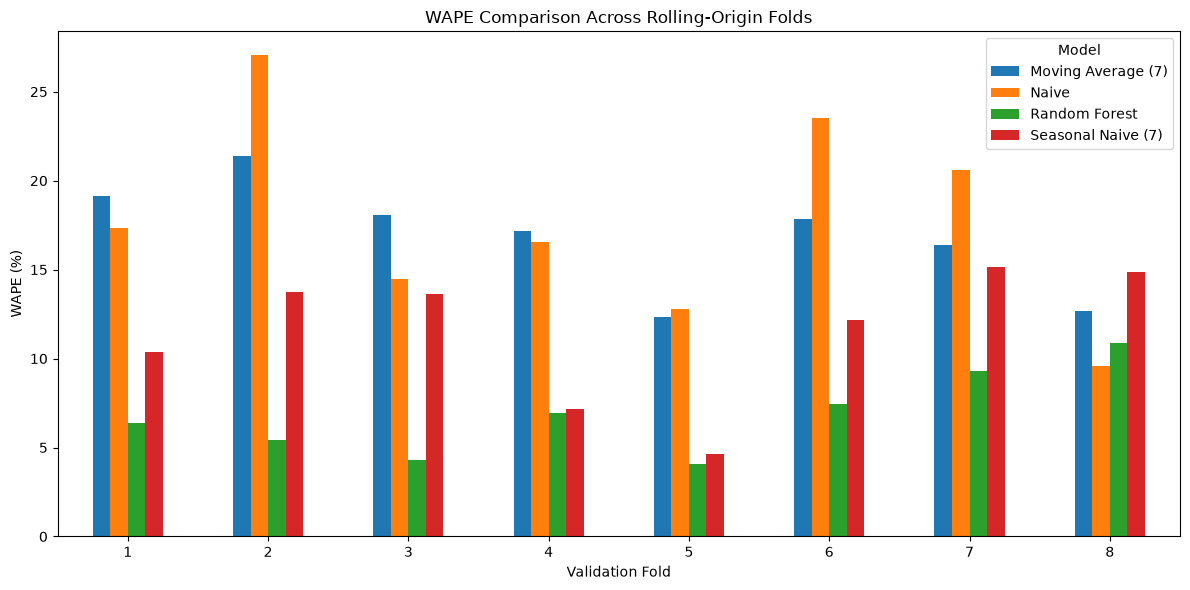

In [10]:
fold_rows = []

for fold_no, subset in all_rolling_results.groupby("fold"):
    for model_name, prediction_col in model_columns.items():
        fold_rows.append({
            "Fold": fold_no,
            "Model": model_name,
            **calculate_metrics(
                subset["actual_sales"],
                subset[prediction_col]
            )
        })

fold_comparison = pd.DataFrame(fold_rows)
display(fold_comparison)

fold_wape = fold_comparison.pivot(
    index="Fold", columns="Model", values="WAPE (%)"
)
ax = fold_wape.plot(kind="bar", figsize=(12, 6))
ax.set_title("WAPE Comparison Across Rolling-Origin Folds")
ax.set_xlabel("Validation Fold")
ax.set_ylabel("WAPE (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 11. Performance by product family

,Family,Model,MAE,RMSE,WAPE (%)
3,BEVERAGES,Random Forest,12098.672461,16364.612286,6.335946
2,BEVERAGES,Seasonal Naive (7),20229.589286,25352.793917,10.594020
1,BEVERAGES,Moving Average (7),34167.901624,40983.056857,17.893365
0,BEVERAGES,Naive,36539.053571,51115.058496,19.135112
7,CLEANING,Random Forest,10700.352733,14846.421779,15.265956
6,CLEANING,Seasonal Naive (7),14441.392857,19182.502979,20.603215
5,CLEANING,Moving Average (7),15379.110442,19594.785397,21.941036
4,CLEANING,Naive,16354.535714,23004.467197,23.332653
11,DAIRY,Random Forest,2363.684555,3080.146754,5.003740
10,DAIRY,Seasonal Naive (7),3944.642857,5090.158042,8.350508


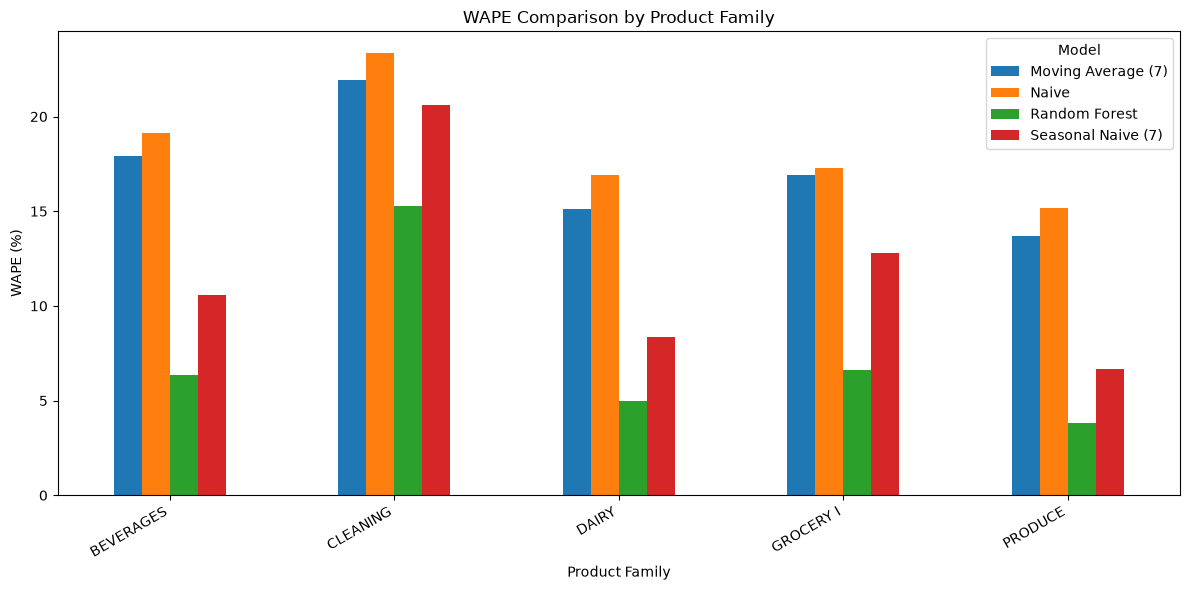

In [11]:
family_rows = []

for family, subset in all_rolling_results.groupby("family"):
    for model_name, prediction_col in model_columns.items():
        family_rows.append({
            "Family": family,
            "Model": model_name,
            **calculate_metrics(
                subset["actual_sales"],
                subset[prediction_col]
            )
        })

family_comparison = pd.DataFrame(family_rows)
display(family_comparison.sort_values(["Family", "WAPE (%)"]))

family_wape = family_comparison.pivot(
    index="Family", columns="Model", values="WAPE (%)"
)
ax = family_wape.plot(kind="bar", figsize=(12, 6))
ax.set_title("WAPE Comparison by Product Family")
ax.set_xlabel("Product Family")
ax.set_ylabel("WAPE (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 12. Export validation predictions and metrics

In [12]:
validation_export = all_rolling_results[[
    "date", "family", "actual_sales", "rf_prediction",
    "naive_prediction", "seasonal_naive_prediction", "fold",
    "training_cutoff"
]].copy()

validation_export["date"] = pd.to_datetime(
    validation_export["date"]
).dt.strftime("%Y-%m-%d")

validation_export["training_cutoff"] = pd.to_datetime(
    validation_export["training_cutoff"]
).dt.strftime("%Y-%m-%d")

validation_export.to_csv(
    OUTPUT_DIR / "validation_predictions.csv",
    index=False
)

overall_comparison.to_csv(
    OUTPUT_DIR / "rolling_validation_metrics.csv",
    index=False
)
fold_comparison.to_csv(
    OUTPUT_DIR / "rolling_validation_metrics_by_fold.csv",
    index=False
)
family_comparison.to_csv(
    OUTPUT_DIR / "rolling_validation_metrics_by_family.csv",
    index=False
)

print("Validation files exported to:", OUTPUT_DIR)


Validation files exported to: C:\Projek\Machine Learning\portfolio\01\retail-sales-forecasting\data\processed


## 13. Final training and 7-day forecast

In [13]:
# Setelah evaluasi selesai, latih model final menggunakan seluruh data aktual.
final_train_data = model_data.copy()
final_train_end = final_train_data["date"].max()

final_forecast_dates = pd.date_range(
    start=final_train_end + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

final_model = build_rf_model(best_params)
final_model.fit(
    final_train_data[FEATURES],
    final_train_data[TARGET]
)

final_forecast = recursive_forecast(
    final_model,
    final_train_data,
    final_forecast_dates
)

final_forecast = final_forecast.rename(
    columns={"prediction": "forecasted_sales"}
)

display(final_forecast.head(10))
print("Final training ends:", final_train_end.date())
print(
    "Forecast period:",
    final_forecast["date"].min().date(),
    "to",
    final_forecast["date"].max().date()
)


,date,family,forecasted_sales
0,2017-08-16,BEVERAGES,164833.955076
1,2017-08-17,BEVERAGES,152538.570024
2,2017-08-18,BEVERAGES,181135.046539
3,2017-08-19,BEVERAGES,208080.595140
4,2017-08-20,BEVERAGES,225069.600902
5,2017-08-21,BEVERAGES,172471.425295
6,2017-08-22,BEVERAGES,156074.029345
7,2017-08-16,CLEANING,54459.907077
8,2017-08-17,CLEANING,51616.909651
9,2017-08-18,CLEANING,56580.803518


Final training ends: 2017-08-15
Forecast period: 2017-08-16 to 2017-08-22


## 14. Export final forecast, parameters and model

In [15]:
import joblib

# ==========================================
# 1. SAVE FINAL FORECAST
# ==========================================

final_forecast_export = final_forecast.copy()

final_forecast_export["date"] = pd.to_datetime(
    final_forecast_export["date"]
).dt.strftime("%Y-%m-%d")

final_forecast_export.to_csv(
    OUTPUT_DIR / "final_forecast.csv",
    index=False
)


# ==========================================
# 2. SAVE BEST PARAMETERS
# ==========================================

with open(MODEL_DIR / "best_rf_params.json", "w") as file:
    json.dump(best_params, file, indent=4)


# ==========================================
# 3. SAVE TRAINED FINAL MODEL
# ==========================================

joblib.dump(
    final_model,
    MODEL_DIR / "final_random_forest.joblib"
)


# ==========================================
# 4. SAVE MODEL METADATA
# ==========================================

metadata = {
    "model_name": "Random Forest Regressor",
    "target": TARGET,
    "features": FEATURES,
    "forecast_horizon": HORIZON,
    "training_end_date": str(model_data["date"].max().date()),
    "best_parameters": best_params
}

with open(MODEL_DIR / "model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4, default=str)


# ==========================================
# 5. CONFIRMATION
# ==========================================

print("Final forecast saved to:", OUTPUT_DIR / "final_forecast.csv")
print("Best parameters saved to:", MODEL_DIR / "best_rf_params.json")
print("Trained model saved to:", MODEL_DIR / "final_random_forest.joblib")
print("Model metadata saved to:", MODEL_DIR / "model_metadata.json")


Final forecast saved to: C:\Projek\Machine Learning\portfolio\01\retail-sales-forecasting\data\processed\final_forecast.csv
Best parameters saved to: C:\Projek\Machine Learning\portfolio\01\retail-sales-forecasting\models\best_rf_params.json
Trained model saved to: C:\Projek\Machine Learning\portfolio\01\retail-sales-forecasting\models\final_random_forest.joblib
Model metadata saved to: C:\Projek\Machine Learning\portfolio\01\retail-sales-forecasting\models\model_metadata.json


Key Findings
1. Model selection: Random Forest merupakan model terbaik dengan WAPE 6,80%, mengungguli seluruh baseline.
2. Model consistency: RF unggul pada 7 dari 8 validation folds, menunjukkan performa yang relatif konsisten.
3. Product-level performance: PRODUCE menjadi kategori dengan prediksi paling akurat, sedangkan CLEANING menjadi kategori yang perlu perhatian lebih.
4. Business implication: Forecast dapat digunakan sebagai salah satu referensi untuk perencanaan penjualan dan pengambilan keputusan operasional, dengan tetap mempertimbangkan ketidakpastian prediksi.